# Machine Learning: Breast Cancer Relapse Prediction

This notebook develops and evaluates machine-learning models to investigate whether gene-expression profiles can predict breast cancer relapse using the GSE2034 dataset.

The analysis will include baseline comparison, feature selection, model training, cross-validation, and performance evaluation.

In [1]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/dashboard_dataset.csv")

# Display dataset dimensions
print("Dataset dimensions:", df.shape)

# Preview the data
df.head()

Dataset dimensions: (286, 11134)


,Sample_Accession,AFFX-BioB-5_at,AFFX-BioB-M_at,AFFX-BioB-3_at,AFFX-BioC-5_at,AFFX-BioC-3_at,AFFX-BioDn-5_at,AFFX-BioDn-3_at,AFFX-CreX-5_at,AFFX-CreX-3_at,...,222368_at,222369_at,222370_x_at,222371_at,222376_at,222379_at,222380_s_at,Relapse,Follow_up_months,ER_status
0,GSM36777,8.869440,9.845176,8.871289,10.421118,10.033698,10.516389,12.921357,13.713247,14.244141,...,8.723149,8.424586,7.238405,7.632268,7.723832,9.786923,8.724855,0,79,ER+
1,GSM36778,9.558421,10.700266,9.960436,11.294104,10.914908,11.228999,13.612592,14.532009,15.116791,...,9.786760,8.101713,7.943687,8.445843,8.229780,9.744498,10.900791,1,50,ER+
2,GSM36779,9.938697,11.032115,10.007448,11.398583,10.922882,11.455533,13.798674,14.843077,15.365475,...,7.921841,7.845490,7.212375,6.378512,8.075212,12.414527,7.541484,0,132,ER+
3,GSM36780,9.812498,10.759722,9.824641,11.428831,10.695402,11.146123,13.480879,14.340789,14.838835,...,8.899659,8.556506,7.583459,7.176921,7.994919,6.933100,8.564531,0,84,ER-
4,GSM36781,9.511950,10.636896,9.315150,11.075747,10.710720,10.665247,13.449084,14.244936,14.727405,...,8.868205,9.603441,8.269127,8.316508,8.199672,6.432959,9.504819,0,147,ER+


## 1. Define the prediction target and features

The target variable is Relapse, which indicates whether a patient experienced relapse (1) or did not experience relapse (0).

Gene-expression measurements will be used as predictors. Clinical variables and sample identifiers will be excluded from this initial model.

In [2]:
# Define target variable
y = df["Relapse"]

# Remove target and non-gene-expression columns from predictors
exclude_columns = [
    "Relapse",
    "ER_status",
    "Sample_Accession",
    "Follow_up_months",
    "Unnamed: 0"
]

X = df.drop(columns=exclude_columns, errors="ignore")

# Inspect dimensions
print("Predictor matrix:", X.shape)
print("Target variable:", y.shape)

# Check target distribution
print("\nRelapse distribution:")
print(y.value_counts())

print("\nRelapse proportions:")
print(y.value_counts(normalize=True))

Predictor matrix: (286, 11130)
Target variable: (286,)

Relapse distribution:
Relapse
0    179
1    107
Name: count, dtype: int64

Relapse proportions:
Relapse
0    0.625874
1    0.374126
Name: proportion, dtype: float64


## 2. Baseline Model (benchmark)

A majority-class classifier will be used as a baseline to establish the minimum predictive performance that a machine-learning model should improve upon.

The classifier predicts the majority outcome for every sample, without using gene-expression information. This dummyclassifier is using the same stratified 5-fold cross validation the rest of the predictive models will use as well, to generate a fair comparison.

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# Create baseline model
baseline = DummyClassifier(strategy="most_frequent")

# Fit and predict
baseline.fit(X, y)
baseline_predictions = baseline.predict(X)

# Evaluate baseline
print("Baseline Accuracy:", accuracy_score(y, baseline_predictions))
print("Baseline Balanced Accuracy:", balanced_accuracy_score(y, baseline_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y, baseline_predictions))

print("\nClassification Report:")
print(classification_report(y, baseline_predictions, zero_division=0))

Baseline Accuracy: 0.6258741258741258
Baseline Balanced Accuracy: 0.5

Confusion Matrix:
[[179   0]
 [107   0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.63      1.00      0.77       179
           1       0.00      0.00      0.00       107

    accuracy                           0.63       286
   macro avg       0.31      0.50      0.38       286
weighted avg       0.39      0.63      0.48       286



## 3. Model Validation Strategy

Stratified nested 5-fold cross-validation will be used to evaluate model performance and optimize hyperparameters.

The outer 5-fold loop will estimate generalization performance, while the inner 5-fold loop will optimize model hyperparameters and feature selection.

All preprocessing, scaling, and feature selection will occur within the cross-validation pipeline to prevent data leakage.

The models that will be compared: 
* baseline majority class dummy classifier
* Linear SVM
* RBF-SVM
* Random Forest
* Regularized logistic regression with elastic net penalty, or lasso logistic regression.

In [ ]:
# Import modelling tools

#Linear SVM Classifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.model_selection import StratifiedKFold, GridSearchCV

from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    recall_score,
    average_precision_score,
    confusion_matrix
)

# Confirm predictors are numeric
X = X.apply(pd.to_numeric, errors="raise")

# Check for missing and infinite values
print("Missing values:", X.isna().sum().sum())
print("Infinite values:", np.isinf(X.to_numpy()).sum())

# Define the modelling pipeline
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("feature_selection", SelectKBest(score_func=f_classif)),
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", class_weight="balanced"))
])

# Hyperparameter search space
param_grid = {
    "feature_selection__k": [25, 50, 100, 250, 500],
    "svm__C": [0.01, 0.1, 1, 10]
}

# Define outer and inner cross-validation
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Store results
fold_results = []

# Nested cross-validation
for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y), start=1):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # Inner loop: hyperparameter optimization
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train, y_train)

    # Evaluate on untouched outer test fold
    best_model = search.best_estimator_

    predictions = best_model.predict(X_test)
    probabilities = best_model.decision_function(X_test)

    # Calculate metrics
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    fold_results.append({
        "Fold": fold,
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions),
        "Sensitivity": recall_score(y_test, predictions, pos_label=1),
        "Specificity": tn / (tn + fp),
        "PR-AUC": average_precision_score(y_test, probabilities),
        "Selected Features": search.best_params_["feature_selection__k"],
        "Best C": search.best_params_["svm__C"]
    })

    print(f"Completed fold {fold}/5")
    print("Best parameters:", search.best_params_)

# Display fold results
results_df = pd.DataFrame(fold_results)

display(results_df)

# Summarize performance
print("\nNested Cross-Validation Results")

for metric in [
    "ROC-AUC",
    "Balanced Accuracy",
    "Sensitivity",
    "Specificity",
    "PR-AUC"
]:
    print(
        f"{metric}: "
        f"{results_df[metric].mean():.3f} "
        f"+/- {results_df[metric].std():.3f}"
    )

Missing values: 0
Infinite values: 0
Completed fold 1/5
Best parameters: {'feature_selection__k': 100, 'svm__C': 0.01}
Completed fold 2/5
Best parameters: {'feature_selection__k': 250, 'svm__C': 0.01}
Completed fold 3/5
Best parameters: {'feature_selection__k': 500, 'svm__C': 0.01}
Completed fold 4/5
Best parameters: {'feature_selection__k': 100, 'svm__C': 0.01}
Completed fold 5/5
Best parameters: {'feature_selection__k': 500, 'svm__C': 0.1}


,Fold,ROC-AUC,Balanced Accuracy,Sensitivity,Specificity,PR-AUC,Selected Features,Best C
0,1,0.715909,0.656566,0.590909,0.722222,0.645746,100,0.01
1,2,0.661376,0.605159,0.571429,0.638889,0.602441,250,0.01
2,3,0.650794,0.640873,0.476190,0.805556,0.590505,500,0.01
3,4,0.701058,0.619048,0.571429,0.666667,0.573446,100,0.01
4,5,0.797403,0.720779,0.727273,0.714286,0.685955,500,0.10



Nested Cross-Validation Results
ROC-AUC: 0.705 +/- 0.058
Balanced Accuracy: 0.648 +/- 0.045
Sensitivity: 0.587 +/- 0.090
Specificity: 0.710 +/- 0.064
PR-AUC: 0.620 +/- 0.046


In [11]:
#Evaluating the DummyClassifier using the nested cross validation, to establish a baseline for performance comparison

from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

baseline_results = []

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y), start=1
):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    baseline = DummyClassifier(strategy="most_frequent")
    baseline.fit(X_train, y_train)

    predictions = baseline.predict(X_test)
    probabilities = baseline.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    baseline_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions),
        "Sensitivity": recall_score(y_test, predictions, pos_label=1),
        "Specificity": tn / (tn + fp),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities)
    })

baseline_df = pd.DataFrame(baseline_results)

display(baseline_df)

print("\nMean baseline performance:")
display(baseline_df.drop(columns="Fold").mean().to_frame("Mean"))

,Fold,Accuracy,Balanced Accuracy,Sensitivity,Specificity,ROC-AUC,PR-AUC
0,1,0.620690,0.5,0.0,1.0,0.5,0.379310
1,2,0.631579,0.5,0.0,1.0,0.5,0.368421
2,3,0.631579,0.5,0.0,1.0,0.5,0.368421
3,4,0.631579,0.5,0.0,1.0,0.5,0.368421
4,5,0.614035,0.5,0.0,1.0,0.5,0.385965



Mean baseline performance:


,Mean
Accuracy,0.625892
Balanced Accuracy,0.500000
Sensitivity,0.000000
Specificity,1.000000
ROC-AUC,0.500000
PR-AUC,0.374108


In [12]:
#RBF-SVM Classifier

rbf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("feature_selection", SelectKBest(score_func=f_classif)),
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        class_weight="balanced"
    ))
])

rbf_param_grid = {
    "feature_selection__k": [25, 50, 100, 250, 500],
    "svm__C": [0.01, 0.1, 1, 10],
    "svm__gamma": ["scale", 0.001, 0.01, 0.1]
}

rbf_fold_results = []
rbf_selected_genes = []

for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y), start=1):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    rbf_search = GridSearchCV(
        estimator=rbf_pipeline,
        param_grid=rbf_param_grid,
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=-1,
        refit=True
    )

    rbf_search.fit(X_train, y_train)

    best_model = rbf_search.best_estimator_

    predictions = best_model.predict(X_test)
    probabilities = best_model.decision_function(X_test)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    selected_indices = best_model.named_steps[
        "feature_selection"
    ].get_support(indices=True)

    selected_gene_names = X.columns[selected_indices].tolist()
    rbf_selected_genes.append(selected_gene_names)

    rbf_fold_results.append({
        "Fold": fold,
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions),
        "Sensitivity": recall_score(y_test, predictions, pos_label=1),
        "Specificity": tn / (tn + fp),
        "PR-AUC": average_precision_score(y_test, probabilities),
        "Selected Features": len(selected_gene_names),
        "Best C": rbf_search.best_params_["svm__C"],
        "Best Gamma": rbf_search.best_params_["svm__gamma"]
    })

rbf_results_df = pd.DataFrame(rbf_fold_results)

display(rbf_results_df.round(3))

,Fold,ROC-AUC,Balanced Accuracy,Sensitivity,Specificity,PR-AUC,Selected Features,Best C,Best Gamma
0,1,0.807,0.726,0.591,0.861,0.731,500,10,scale
1,2,0.694,0.609,0.524,0.694,0.581,500,1,0.001
2,3,0.626,0.603,0.429,0.778,0.602,500,10,0.001
3,4,0.725,0.631,0.429,0.833,0.650,100,10,scale
4,5,0.790,0.695,0.591,0.800,0.711,500,10,scale


In [13]:
# Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

# Define Random Forest pipeline
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("feature_selection", SelectKBest(score_func=f_classif)),
    ("rf", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Hyperparameter search space
rf_param_grid = {
    "feature_selection__k": [25, 50, 100, 250, 500],
    "rf__n_estimators": [200, 500],
    "rf__max_depth": [None, 5, 10],
    "rf__min_samples_leaf": [1, 3, 5]
}

# Store results
rf_fold_results = []

# Nested cross-validation
for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y), start=1
):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # Inner loop: hyperparameter optimization
    rf_search = GridSearchCV(
        estimator=rf_pipeline,
        param_grid=rf_param_grid,
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=-1,
        refit=True
    )

    rf_search.fit(X_train, y_train)

    # Evaluate on untouched outer test fold
    best_rf = rf_search.best_estimator_

    predictions = best_rf.predict(X_test)
    probabilities = best_rf.predict_proba(X_test)[:, 1]

    # Calculate confusion matrix metrics
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    rf_fold_results.append({
        "Fold": fold,
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Sensitivity": recall_score(
            y_test, predictions, pos_label=1
        ),
        "Specificity": tn / (tn + fp),
        "PR-AUC": average_precision_score(
            y_test, probabilities
        ),
        "Selected Features": rf_search.best_params_[
            "feature_selection__k"
        ],
        "Best Parameters": rf_search.best_params_
    })

    print(f"Completed fold {fold}/5")
    print("Best parameters:", rf_search.best_params_)

# Display results
rf_results_df = pd.DataFrame(rf_fold_results)

display(rf_results_df.drop(columns="Best Parameters"))

# Summarize performance
print("\nRandom Forest Nested Cross-Validation Results")

for metric in [
    "ROC-AUC",
    "Balanced Accuracy",
    "Sensitivity",
    "Specificity",
    "PR-AUC"
]:
    print(
        f"{metric}: "
        f"{rf_results_df[metric].mean():.3f} "
        f"+/- {rf_results_df[metric].std():.3f}"
    )

Completed fold 1/5
Best parameters: {'feature_selection__k': 500, 'rf__max_depth': None, 'rf__min_samples_leaf': 5, 'rf__n_estimators': 500}
Completed fold 2/5
Best parameters: {'feature_selection__k': 500, 'rf__max_depth': None, 'rf__min_samples_leaf': 5, 'rf__n_estimators': 200}
Completed fold 3/5
Best parameters: {'feature_selection__k': 500, 'rf__max_depth': None, 'rf__min_samples_leaf': 3, 'rf__n_estimators': 200}
Completed fold 4/5
Best parameters: {'feature_selection__k': 25, 'rf__max_depth': None, 'rf__min_samples_leaf': 1, 'rf__n_estimators': 500}
Completed fold 5/5
Best parameters: {'feature_selection__k': 500, 'rf__max_depth': 5, 'rf__min_samples_leaf': 1, 'rf__n_estimators': 200}


,Fold,ROC-AUC,Balanced Accuracy,Sensitivity,Specificity,PR-AUC,Selected Features
0,1,0.700758,0.661616,0.545455,0.777778,0.568964,500
1,2,0.685185,0.636905,0.523810,0.750000,0.570510,500
2,3,0.604497,0.547619,0.428571,0.666667,0.478204,500
3,4,0.573413,0.529762,0.476190,0.583333,0.460848,25
4,5,0.746753,0.666883,0.590909,0.742857,0.680419,500



Random Forest Nested Cross-Validation Results
ROC-AUC: 0.662 +/- 0.071
Balanced Accuracy: 0.609 +/- 0.065
Sensitivity: 0.513 +/- 0.063
Specificity: 0.704 +/- 0.079
PR-AUC: 0.552 +/- 0.088


### Copilots Recommendation
Testing out Copilots recommendation (as required by the AI Productivity Declaration). Copilot recommended a regularized logistic regression with elastic net penalty, or lasso logistic regression.

In [14]:
from sklearn.linear_model import LogisticRegression

elastic_net_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("feature_selection", SelectKBest(score_func=f_classif)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        penalty="elasticnet",
        solver="saga",
        class_weight="balanced",
        max_iter=10000,
        random_state=42
    ))
])

elastic_net_param_grid = {
    "feature_selection__k": [25, 50, 100, 250, 500],
    "model__C": [0.001, 0.01, 0.1, 1, 10],
    "model__l1_ratio": [0, 0.25, 0.5, 0.75, 1]
}

elastic_net_fold_results = []
elastic_net_selected_genes = []

for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y), start=1):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    elastic_net_search = GridSearchCV(
        estimator=elastic_net_pipeline,
        param_grid=elastic_net_param_grid,
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=-1,
        refit=True
    )

    elastic_net_search.fit(X_train, y_train)

    best_model = elastic_net_search.best_estimator_

    predictions = best_model.predict(X_test)
    probabilities = best_model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    # Identify genes retained by ANOVA
    selected_indices = best_model.named_steps[
        "feature_selection"
    ].get_support(indices=True)

    selected_gene_names = X.columns[selected_indices].tolist()
    elastic_net_selected_genes.append(selected_gene_names)

    # Identify genes with non-zero logistic regression coefficients
    coefficients = best_model.named_steps["model"].coef_[0]

    nonzero_genes = [
        gene for gene, coefficient in zip(
            selected_gene_names, coefficients
        )
        if not np.isclose(coefficient, 0)
    ]

    elastic_net_fold_results.append({
        "Fold": fold,
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions),
        "Sensitivity": recall_score(y_test, predictions, pos_label=1),
        "Specificity": tn / (tn + fp),
        "PR-AUC": average_precision_score(y_test, probabilities),
        "ANOVA Features": len(selected_gene_names),
        "Nonzero Coefficients": len(nonzero_genes),
        "Best C": elastic_net_search.best_params_["model__C"],
        "Best L1 Ratio": elastic_net_search.best_params_["model__l1_ratio"]
    })

elastic_net_results_df = pd.DataFrame(elastic_net_fold_results)

display(elastic_net_results_df.round(3))

c:\Users\Sara\Documents\CIND820\gse2034-research-dashboard\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Sara\Documents\CIND820\gse2034-research-dashboard\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=Non

,Fold,ROC-AUC,Balanced Accuracy,Sensitivity,Specificity,PR-AUC,ANOVA Features,Nonzero Coefficients,Best C,Best L1 Ratio
0,1,0.794,0.730,0.682,0.778,0.697,500,500,0.01,0
1,2,0.680,0.643,0.619,0.667,0.600,500,500,0.01,0
2,3,0.655,0.603,0.429,0.778,0.636,500,500,0.10,0
3,4,0.704,0.571,0.476,0.667,0.567,100,100,0.10,0
4,5,0.788,0.721,0.727,0.714,0.766,500,500,0.01,0


,Baseline,Linear SVM,RBF SVM,Random Forest,Logistic Regression (Ridge)
ROC-AUC,0.500,0.705,0.728,0.662,0.724
Balanced Accuracy,0.500,0.648,0.653,0.609,0.654
Sensitivity,0.000,0.587,0.513,0.513,0.587
Specificity,1.000,0.710,0.793,0.704,0.721
PR-AUC,0.374,0.620,0.655,0.552,0.653


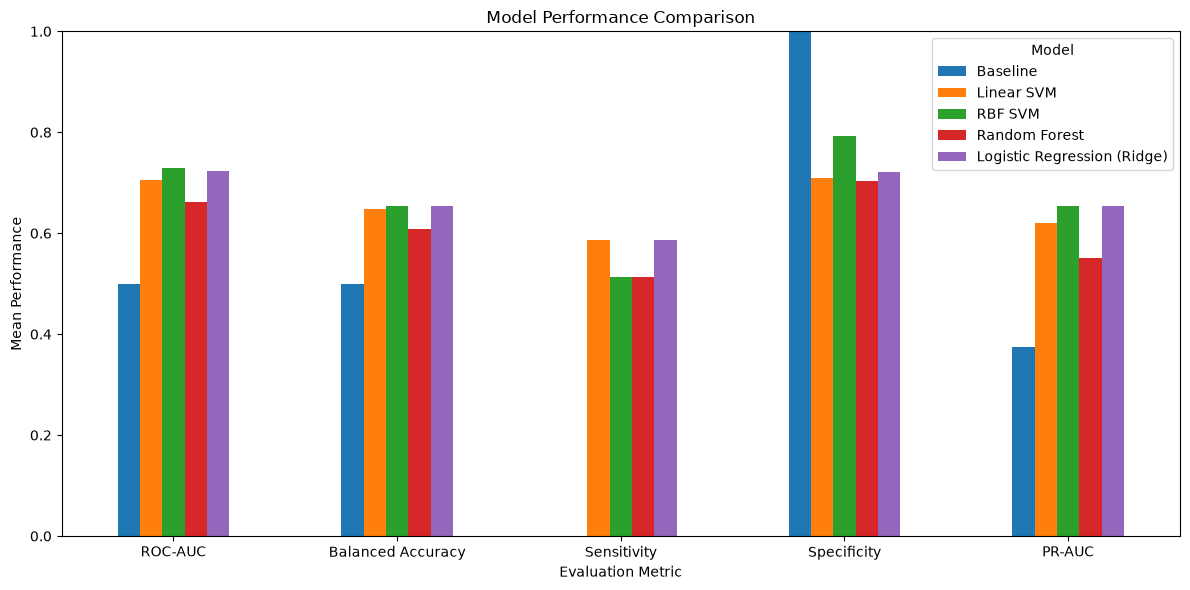

In [16]:

# Compare model performance

comparison = pd.DataFrame({
    "Baseline": {
        "ROC-AUC": baseline_df["ROC-AUC"].mean(),
        "Balanced Accuracy": baseline_df["Balanced Accuracy"].mean(),
        "Sensitivity": baseline_df["Sensitivity"].mean(),
        "Specificity": baseline_df["Specificity"].mean(),
        "PR-AUC": baseline_df["PR-AUC"].mean()
    },

    "Linear SVM": {
        "ROC-AUC": results_df["ROC-AUC"].mean(),
        "Balanced Accuracy": results_df["Balanced Accuracy"].mean(),
        "Sensitivity": results_df["Sensitivity"].mean(),
        "Specificity": results_df["Specificity"].mean(),
        "PR-AUC": results_df["PR-AUC"].mean()
    },

    "RBF SVM": {
        "ROC-AUC": rbf_results_df["ROC-AUC"].mean(),
        "Balanced Accuracy": rbf_results_df["Balanced Accuracy"].mean(),
        "Sensitivity": rbf_results_df["Sensitivity"].mean(),
        "Specificity": rbf_results_df["Specificity"].mean(),
        "PR-AUC": rbf_results_df["PR-AUC"].mean()
    },

    "Random Forest": {
        "ROC-AUC": rf_results_df["ROC-AUC"].mean(),
        "Balanced Accuracy": rf_results_df["Balanced Accuracy"].mean(),
        "Sensitivity": rf_results_df["Sensitivity"].mean(),
        "Specificity": rf_results_df["Specificity"].mean(),
        "PR-AUC": rf_results_df["PR-AUC"].mean()
    },

    "Logistic Regression (Ridge)": {
        "ROC-AUC": elastic_net_results_df["ROC-AUC"].mean(),
        "Balanced Accuracy": elastic_net_results_df["Balanced Accuracy"].mean(),
        "Sensitivity": elastic_net_results_df["Sensitivity"].mean(),
        "Specificity": elastic_net_results_df["Specificity"].mean(),
        "PR-AUC": elastic_net_results_df["PR-AUC"].mean()
    }
})

display(comparison.round(3))

# Visualize model performance

comparison.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Model Performance Comparison")
plt.ylabel("Mean Performance")
plt.xlabel("Evaluation Metric")
plt.legend(title="Model")
plt.tight_layout()
plt.show()
